# **EDA 실습 03**


# **데이터셋 설명**
데이터 출처: Video Game Sales (Kaggle, vgchartz.com 판매량 집계 기반) — 1980~2017년 출시 게임 16,539종

| 컬럼명 | 설명 |
|---|---|
| Name | 게임 이름 |
| Platform | 출시 플랫폼 (Wii, PS4, NES 등) |
| Year | 출시 연도 |
| Genre | 장르 |
| Publisher | 배급사 |
| NA_Sales | 북미 판매량 (단위: 백만 장) |
| EU_Sales | 유럽 판매량 (단위: 백만 장) |
| JP_Sales | 일본 판매량 (단위: 백만 장) |
| Other_Sales | 그 외 지역 판매량 (단위: 백만 장) |
| Global_Sales | 전세계 판매량 (단위: 백만 장) |

In [117]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/videogame_sales.csv")
df = pd.read_csv('EDA실습_03_input.csv')
df.head()

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Kaboom!,2600,1980.0,Misc,Activision,1.07,0.07,0.0,0.01,1.15
1,Boxing,2600,1980.0,Fighting,Activision,0.72,0.04,0.0,0.01,0.77
2,Ice Hockey,2600,1980.0,Sports,Activision,0.46,0.03,0.0,0.01,0.49
3,Freeway,2600,1980.0,Action,Activision,0.32,0.02,0.0,0.00,0.34
4,Bridge,2600,1980.0,Misc,Activision,0.25,0.02,0.0,0.00,0.27


In [118]:
ans = []

#### **Q1. 전 세계에서 가장 많이 팔린 게임은 무엇일까?**

- 테트리스, 마리오, 포켓몬 게임중 하나일 것 같다.
- 이 가설을 검증할 정보를 찾고 시각화한다.
- 전세게 판매량 (global 기준) 6위 게임의 이름을 구하라.

In [119]:
q1 = df.sort_values('Global_Sales', ascending=False)['Name'].iloc[5]
ans.append(q1)

#### **Q2. 닌텐도는의 게임의 인기는 대륙별로 다를까?**

- 북미, 유럽 유저와 일본 유저의 성향이 달라 선호하는 게임이 달랐을 것으로 예상한다.
- 이 가설을 검증할 정보를 찾고 시각화한다.
- [1] 글로벌 판매량 top 10게임 중 일본 게임 유저들이 가장 많이 구매한 게임명을 찾아라.

  [2] 글로벌 판매량 top 10 북미에서 일본보다 압도적으로 많이 팔린 게임이 몇배나 많이 팔렸는지를 소수점 2자리까지 구하라.

In [120]:
temp = df.sort_values('Global_Sales', ascending=False).iloc[:10]

jp_top_name = temp.sort_values('JP_Sales', ascending=False)['Name'].iloc[0]
q2_1 = jp_top_name

q2_2 = round((temp['NA_Sales'] / temp['JP_Sales']).max(), 2)

ans.append(q2_1)
ans.append(q2_2)

#### **Q3. 일본과 북미는 좋아하는 장르가 다를까?**

- 이 가설을 검증할 정보를 찾고 시각화한다.
- 일본이 북미보다 선호하는 (판매량이 많은) 유일한 게임 장르를 찾는다.

In [121]:
temp = df.groupby('Genre')[['JP_Sales', 'NA_Sales']].sum()

only_jp = temp[temp['JP_Sales'] > temp['NA_Sales']].index[0]
q3 = only_jp

ans.append(q3)

#### **Q4. 게임 판매량은 최근으로 올수록 계속 늘어났을까?**

- 게임 산업이 계속 성장해왔으니, 판매량도 최근 연도일수록 더 많을 것 같다.
- 이 가설을 검증할 정보를 찾고 시각화한다.
- 연도별 전세계 판매량 합계를 선 그래프로 그리고, 판매량이 가장 많았던 연도를 찾아라.(정수로 저장한다)

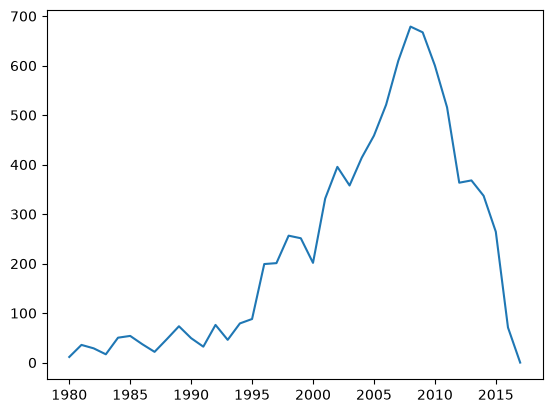

In [ ]:
df.head(2)

YearSales_sum = df.groupby('Year')['Global_Sales'].sum()

plt.plot(YearSales_sum)
plt.show()

best_year = int(YearSales_sum.idxmax())
q4 = best_year

ans.append(q4)

#### **Q5. 닌텐도가 만든 게임은 평균적으로 훨씬 많이 팔릴까?**

- 닌텐도는 마리오, 젤다처럼 확실한 인기 IP가 많으니, 게임 한 편당 평균 판매량도 다른 회사보다 훨씬 높을 것 같다.
- 이 가설을 검증할 정보를 찾고 시각화한다.
- 닌텐도(Nintendo)가 배급한 게임과 그 외 게임의 평균 전세계 판매량을 구하고, 두 값의 차이를 소수점 2자리까지 구한다.

In [123]:
df.head()

nin_mean = df[df['Publisher']=='Nintendo']['Global_Sales'].mean()
other_mean = df[df['Publisher']!='Nintendo']['Global_Sales'].mean()

q5 = round((nin_mean - other_mean), 2)

ans.append(q5)

### **Q6. 제출**

- 위에서 찾은 각 정보들을 DataFrame의 "ans" 컬럼에 순서대로 담아 .csv 파일로 저장하여 제출한다.
- 총 기입되는 행의 개수는 6개이다.

In [124]:
no = pd.DataFrame([i for i in range(6)], columns=['question_no'])
ans = pd.DataFrame(ans, columns=['ans'])

result = pd.concat([no, ans], axis=1)

result.to_csv("EDA실습_03_output.csv", index=False)